In [1]:
import re
import string
import itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from wordcloud import WordCloud, STOPWORDS
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer


from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.cluster import Birch
from numpy import unique
from sklearn.mixture import GaussianMixture
from sklearn.cluster import SpectralClustering


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MaenQawasmeh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\MaenQawasmeh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MaenQawasmeh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Read Data

In [2]:
Training_data = pd.read_csv('Train_set.csv')
Testing_data=pd.read_csv('Test_set.csv')

In [3]:
def drop_unnamed(df):
    return df.loc[:, ~df.columns.str.contains(r"^Unnamed")]

Training_data = drop_unnamed(Training_data)
Testing_data = drop_unnamed(Testing_data)

# EDA

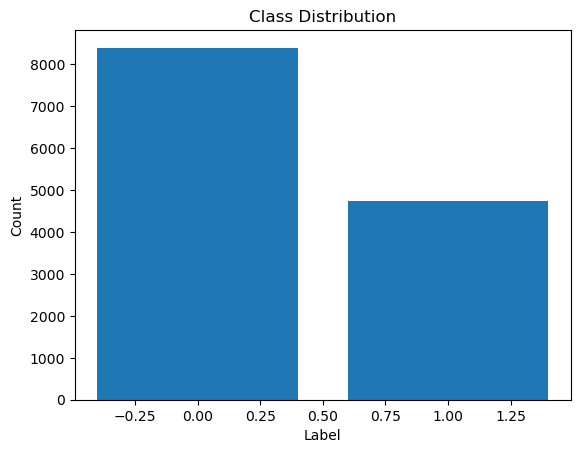

In [4]:
label_counts = Training_data['Label'].value_counts()
plt.bar(label_counts.index, label_counts.values)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Class Distribution')
plt.show()

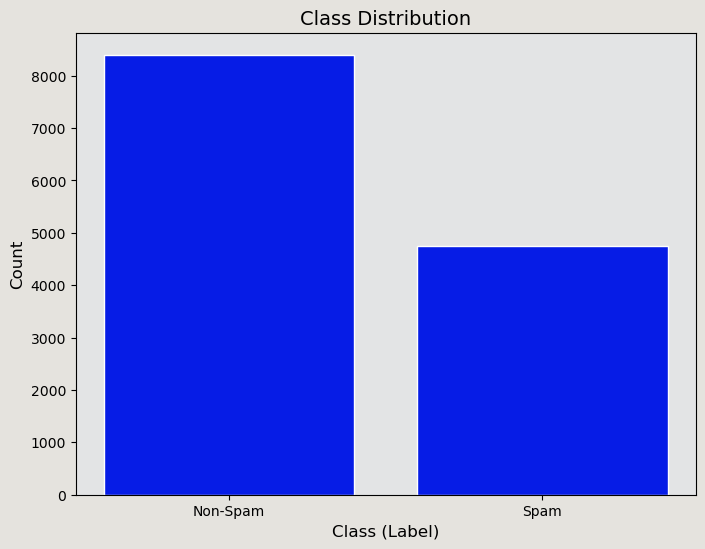

In [5]:

class_counts = Training_data['Label'].value_counts()

plt.figure(figsize=(8, 6))

plt.gcf().set_facecolor('#e5e3de') 
plt.gca().set_facecolor('#e3e4e5')

categories = ['Non-Spam', 'Spam']
counts = [class_counts[0], class_counts[1]]

plt.bar(categories, counts, color="#061ce6", edgecolor='white')

plt.title('Class Distribution', fontsize=14)
plt.xlabel('Class (Label)', fontsize=12)
plt.ylabel('Count', fontsize=12)

# 5. عرض الرسمة
plt.show()

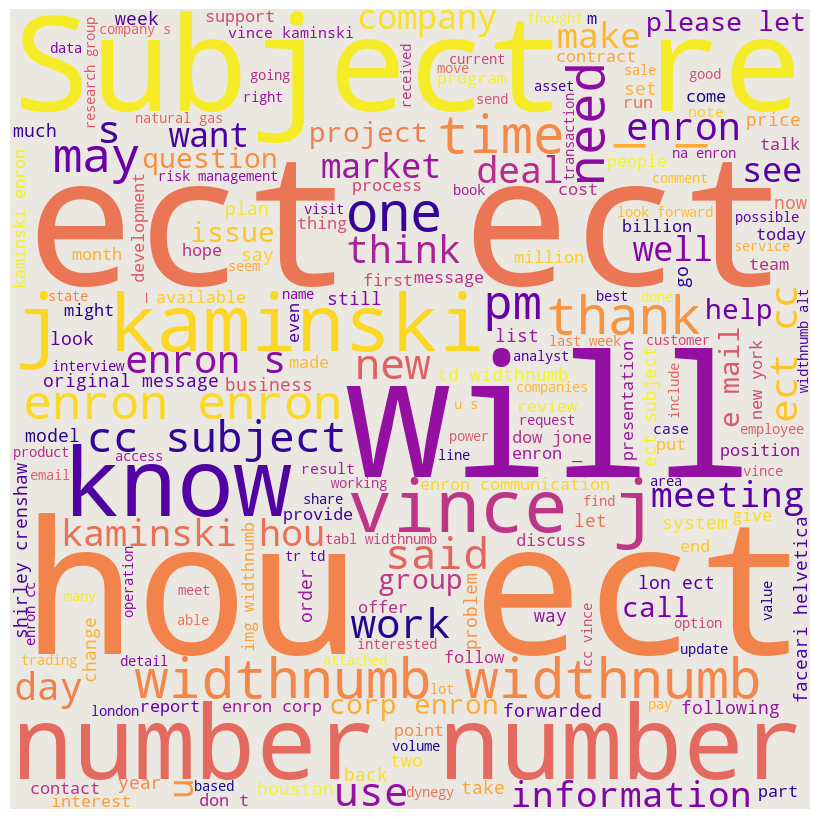

In [6]:
non_spam_data = Training_data[Training_data['Label'] == 0]
non_spam_text = " ".join(str(item) for item in non_spam_data['Body'])

stopwords_non_spam_data = set(STOPWORDS)
wordcloud = WordCloud(
    width=800, 
    height=800,
    background_color='#ebe8e1', 
    stopwords=stopwords_non_spam_data,
    colormap='plasma', 
    min_font_size=10
).generate(non_spam_text)

plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # إخفاء المحاور
plt.tight_layout(pad=0)

plt.show()

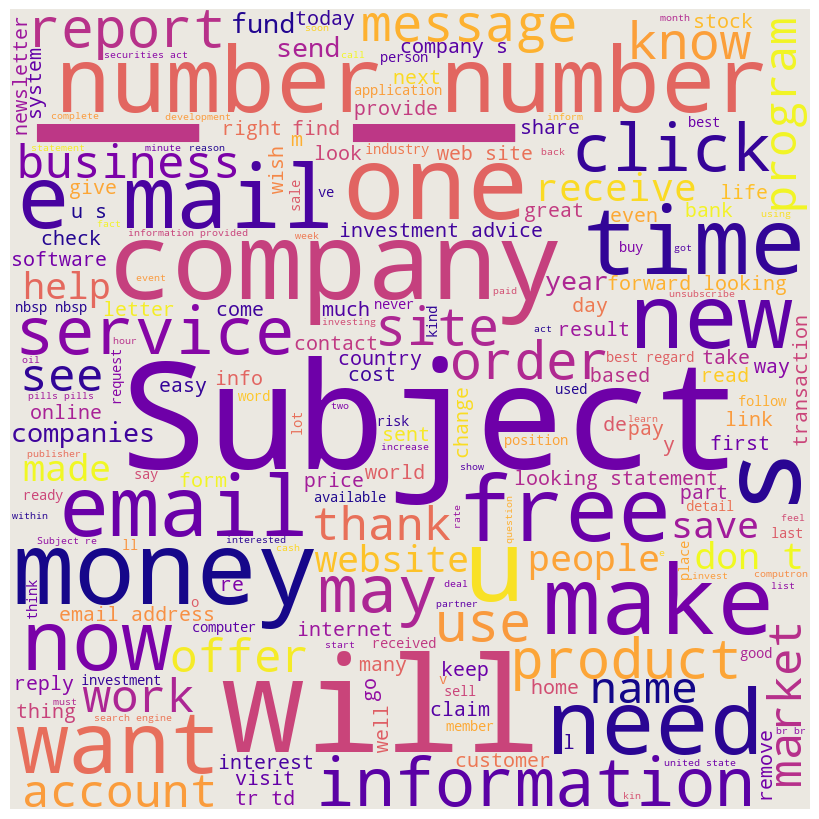

In [7]:
spam_data = Training_data[Training_data['Label'] == 1]
spam_text = " ".join(str(item) for item in spam_data['Body'])

stopwords_spam_data = set(STOPWORDS)
wordcloud = WordCloud(
    width=800, 
    height=800,
    background_color='#ebe8e1', 
    stopwords=stopwords_spam_data,
    colormap='plasma', 
    min_font_size=10
).generate(spam_text)

plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # إخفاء المحاور
plt.tight_layout(pad=0)

plt.show()

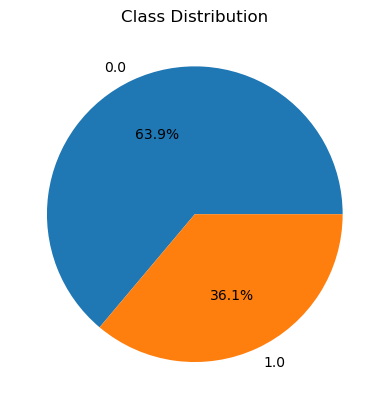

In [8]:

label_counts = Training_data['Label'].value_counts()
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%')
plt.title('Class Distribution')
plt.show()

# Clean Data 

# Lowercasing

In [9]:
def clean_text(series):
    return series.fillna("").str.lower()

Training_data['Body'] = clean_text(Training_data['Body'])
Testing_data['Body'] = clean_text(Testing_data['Body'])

# clean Space 

In [10]:
Training_data['Body'] = Training_data['Body'].str.replace(r'\s+', ' ', regex=True).str.strip()
Testing_data['Body'] = Testing_data['Body'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Remove numbers


In [11]:
Training_data['Body'] = Training_data['Body'].str.replace(r'\d+', '', regex=True)
Testing_data['Body'] = Testing_data['Body'].str.replace(r'\d+', '', regex=True)

# Tokenization


In [12]:
Training_data['Body'] = Training_data['Body'].apply(word_tokenize)
Testing_data['Body'] = Testing_data['Body'].apply(word_tokenize)

# Stopword removal

In [13]:
stop_words = set(list(string.punctuation) + stopwords.words('english'))

Training_data['Body'] = Training_data['Body'].apply(lambda x: [word for word in x if word not in stop_words])
Testing_data['Body'] = Testing_data['Body'].apply(lambda x: [word for word in x if word not in stop_words])

# Flatten

In [14]:
all_words = list(itertools.chain.from_iterable(Training_data['Body']))

# Count word frequencies

In [15]:
word_counts = Counter(all_words)

# Get the most common words

In [16]:
most_common_words = [word for word, count in word_counts.most_common(10)]


# remove_common_words

In [17]:
most_common_set = set(most_common_words)

def remove_common_words(words):
    return [word for word in words if word not in most_common_set]


Training_data['Body'] = Training_data['Body'].apply(remove_common_words)
Testing_data['Body'] = Testing_data['Body'].apply(remove_common_words)

# Text Reconstruction

In [18]:
Training_data['Body'] = Training_data['Body'].apply(lambda x: ' '.join(x))
Testing_data['Body'] = Testing_data['Body'].apply(lambda x: ' '.join(x))

# clean Space 

In [19]:
Training_data['Body'] = Training_data['Body'].str.replace(r'\s{2,}', ' ', regex=True).str.strip()
Testing_data['Body'] = Testing_data['Body'].str.replace(r'\s{2,}', ' ', regex=True).str.strip()

# Horizontal Bar Chart

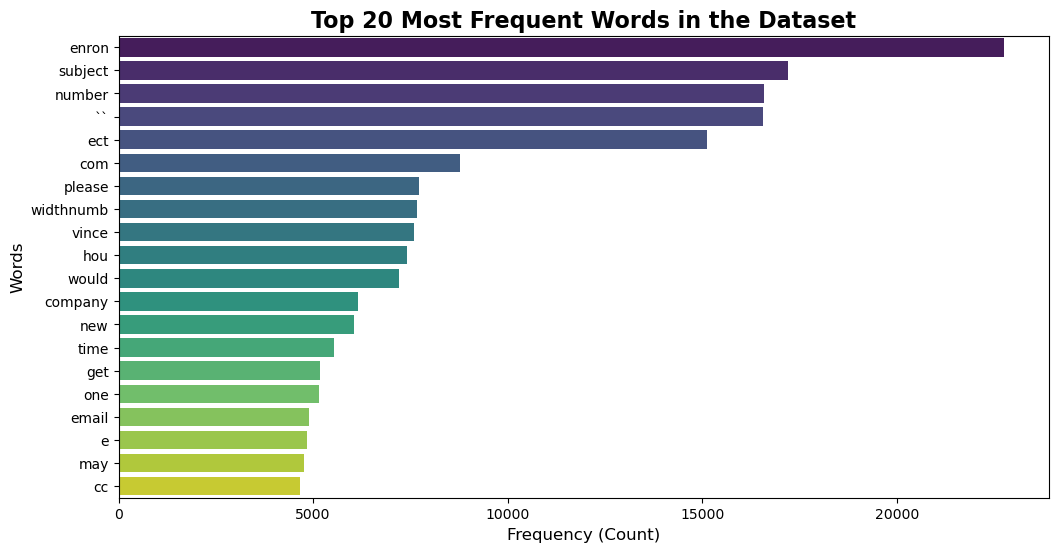

In [20]:
top_20_words = word_counts.most_common(20)

words = [item[0] for item in top_20_words]
counts = [item[1] for item in top_20_words]
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=words, palette='viridis', hue=words, legend=False)
plt.title('Top 20 Most Frequent Words in the Dataset', fontsize=16, fontweight='bold')
plt.xlabel('Frequency (Count)', fontsize=12)
plt.ylabel('Words', fontsize=12)
plt.show()

In [21]:
X = Training_data['Body']
y = Training_data['Label']

X_test = Testing_data['Body']

# TF-IDF

In [22]:
vect = TfidfVectorizer(
    ngram_range=(1, 5),
    smooth_idf=False,
    max_features=1000,
    sublinear_tf=False
)

X_vect = vect.fit_transform(X)        
X_test_vect = vect.transform(X_test)  

In [23]:
X_vect.shape, X_test_vect.shape

((13153, 1000), (5638, 1000))

# MiniBatchKMeans

In [24]:
model_mini = MiniBatchKMeans(
    n_clusters=2,
    init='k-means++',
    random_state=42,
    tol=1e-4
)
model_mini.fit(X_vect)
train_cluster_labels = model_mini.predict(X_vect)
class_report = classification_report(y, train_cluster_labels)

print("Classification Report:")
print(class_report)

c:\Users\MaenQawasmeh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    h

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.72      0.83      8400
         1.0       0.66      0.97      0.79      4753

    accuracy                           0.81     13153
   macro avg       0.82      0.85      0.81     13153
weighted avg       0.86      0.81      0.82     13153



In [25]:
# Calculate the precision
from sklearn.metrics import precision_score
precision = precision_score(y, train_cluster_labels, average='weighted')
print("Precision: {:.2f}".format(precision))

Precision: 0.86


In [26]:
test_data_vect = vect.transform(Testing_data['Body'])

test_cluster_labels = model_mini.predict(test_data_vect)


submission_df = pd.DataFrame({'ID': Testing_data['id'],'Label': test_cluster_labels})

submission_df.to_csv('miniKmeans_Submission.csv', index=False)

# Kmean


In [27]:
k_means = KMeans(algorithm='lloyd', copy_x=False, init='random', max_iter=300,n_clusters=2, n_init=10, random_state=42, tol=0.0001, verbose=0)
k_means.fit(X_vect)

train_cluster_labels_kmean = k_means.predict(X_vect)
class_report = classification_report(y,train_cluster_labels_kmean )

print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

         0.0       0.39      0.36      0.37      8400
         1.0       0.01      0.01      0.01      4753

    accuracy                           0.23     13153
   macro avg       0.20      0.18      0.19     13153
weighted avg       0.25      0.23      0.24     13153



In [28]:
acc_original = accuracy_score(y, train_cluster_labels_kmean)
acc_flipped = accuracy_score(y, 1 - train_cluster_labels_kmean)

if acc_flipped > acc_original:
    train_cluster_labels_kmean = 1 - train_cluster_labels_kmean

class_report = classification_report(y, train_cluster_labels_kmean)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.64      0.78      8400
         1.0       0.61      0.99      0.76      4753

    accuracy                           0.77     13153
   macro avg       0.80      0.82      0.77     13153
weighted avg       0.85      0.77      0.77     13153



In [29]:
test_data_vect = vect.transform(Testing_data['Body'])

test_cluster_labels_kmean = k_means.predict(test_data_vect)

if acc_flipped > acc_original:
    test_cluster_labels_kmean = 1 - test_cluster_labels_kmean

submission_df_kmean = pd.DataFrame({'ID': Testing_data['id'], 'Label': test_cluster_labels_kmean})

submission_df_kmean.to_csv('Kmeans_Submission.csv', index=False)

# Birch

In [30]:
model_br = Birch(threshold=0.01, n_clusters=2)
model_br.fit(X_vect)

yhat_br = model_br.predict(X_vect)

acc_original = accuracy_score(y, yhat_br)
acc_flipped = accuracy_score(y, 1 - yhat_br)

if acc_flipped > acc_original:
    yhat_br = 1 - yhat_br

class_report_br = classification_report(y, yhat_br)
print("Classification Report (Birch):")
print(class_report_br)

Classification Report (Birch):
              precision    recall  f1-score   support

         0.0       0.90      0.71      0.80      8400
         1.0       0.63      0.86      0.73      4753

    accuracy                           0.77     13153
   macro avg       0.76      0.79      0.76     13153
weighted avg       0.80      0.77      0.77     13153



In [31]:

test_cluster_labels_br = model_br.predict(test_data_vect)

if acc_flipped > acc_original:
    test_cluster_labels_br = 1 - test_cluster_labels_br

submission_df_br = pd.DataFrame({'ID': Testing_data['id'],'Label': test_cluster_labels_br})

submission_df_br.to_csv('Birch_Submission.csv', index=False)

# Spectral Clustering

In [32]:

model_sc = SpectralClustering(n_clusters=2)

yhat_sc = model_sc.fit_predict(X_vect)

clusters_sc = np.unique(yhat_sc)
print("Clusters of Spectral Clustering:", clusters_sc)

acc_original = accuracy_score(y, yhat_sc)
acc_flipped = accuracy_score(y, 1 - yhat_sc)

if acc_flipped > acc_original:
    yhat_sc = 1 - yht_sc

class_report_sc = classification_report(y, yhat_sc)
print("Classification Report (Spectral Clustering):")
print(class_report_sc)

Clusters of Spectral Clustering: [0 1]
Classification Report (Spectral Clustering):
              precision    recall  f1-score   support

         0.0       0.64      0.99      0.77      8400
         1.0       0.00      0.00      0.00      4753

    accuracy                           0.63     13153
   macro avg       0.32      0.49      0.39     13153
weighted avg       0.41      0.63      0.49     13153



# Gaussian Mixture Model

In [ ]:
data_X = X_vect.toarray()

model_gb = GaussianMixture(n_components=2,covariance_type='diag',random_state=42)

model_gb.fit(data_X)
yhat_gb = model_gb.predict(data_X)

acc_original = accuracy_score(y, yhat_gb)
acc_flipped = accuracy_score(y, 1 - yhat_gb)

if acc_flipped > acc_original:
    yhat_gb = 1 - yhat_gb

class_report_gb = classification_report(y, yhat_gb)
print("Classification Report (Gaussian Mixture Model):")
print(class_report_gb)

Classification Report (Gaussian Mixture Model):
              precision    recall  f1-score   support

         0.0       0.85      0.74      0.79      8400
         1.0       0.62      0.77      0.69      4753

    accuracy                           0.75     13153
   macro avg       0.73      0.75      0.74     13153
weighted avg       0.77      0.75      0.75     13153



C:\Users\MaenQawasmeh\AppData\Local\Temp\ipykernel_13148\3195868326.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=models, y=precisions, palette=colors)


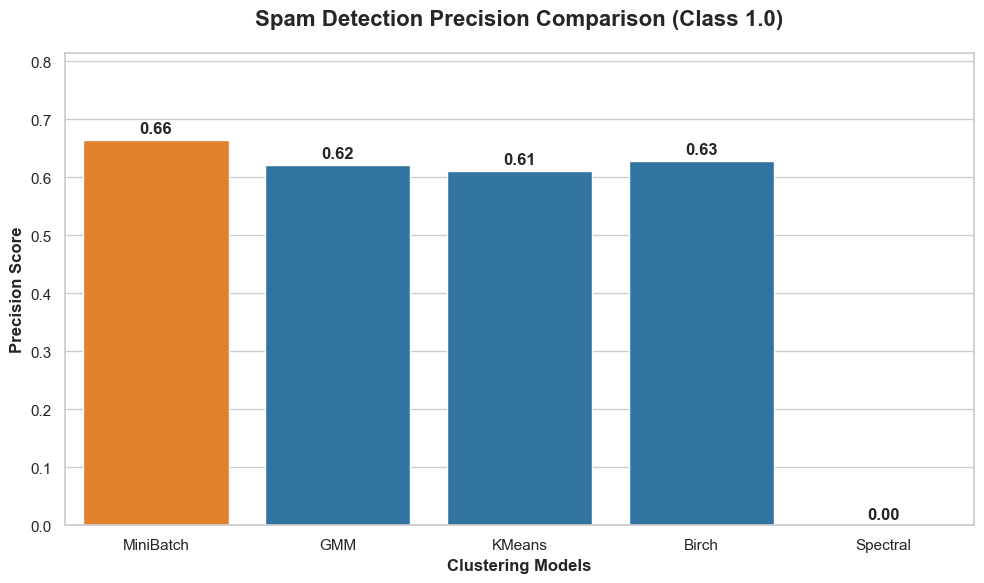

In [ ]:
p_mini = precision_score(y, train_cluster_labels, pos_label=1)
p_gmm = precision_score(y, yhat_gb, pos_label=1)
p_kmeans = precision_score(y, train_cluster_labels_kmean, pos_label=1)
p_birch = precision_score(y, yhat_br, pos_label=1)
p_spectral = precision_score(y, yhat_sc, pos_label=1)

models = ['MiniBatch', 'GMM', 'KMeans', 'Birch', 'Spectral']
precisions = [p_mini, p_gmm, p_kmeans, p_birch, p_spectral]

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

max_precision = max(precisions)
colors = ['#ff7f0e' if p == max_precision else '#1f77b4' for p in precisions]

ax = sns.barplot(x=models, y=precisions, palette=colors)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 8), 
                textcoords='offset points',
                fontsize=12, fontweight='bold')

plt.title('Spam Detection Precision Comparison (Class 1.0)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Clustering Models', fontsize=12, fontweight='bold')
plt.ylabel('Precision Score', fontsize=12, fontweight='bold')
plt.ylim(0, max(precisions) + 0.15)
plt.tight_layout()
plt.show()

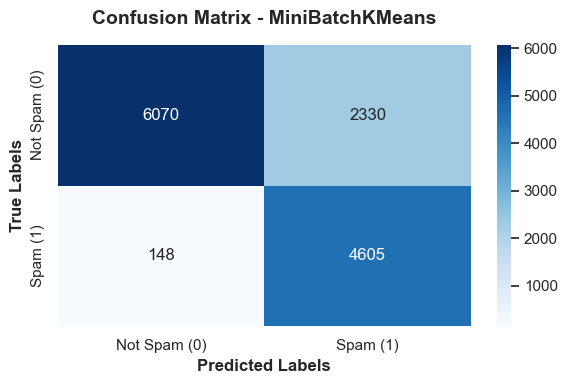

In [36]:
cm = confusion_matrix(y, train_cluster_labels)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Not Spam (0)', 'Spam (1)'], 
            yticklabels=['Not Spam (0)', 'Spam (1)'])

plt.xlabel('Predicted Labels', fontsize=12, fontweight='bold')
plt.ylabel('True Labels', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - MiniBatchKMeans', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()